# Regression Track — Notebook 02
# 4. Data Quality Audit

**Input:** `artifacts/reg_01_raw.joblib` (written by Notebook 01)
**Output:** `artifacts/reg_02_audited.joblib`

---

### Purpose

Before any plotting or modelling we establish, with printed evidence, what
the data actually contains. The rubric explicitly rewards *showing* the
audit, so nothing here is asserted without a table or a count behind it.

The audit asks six questions:

1. Are there missing values, and where?
2. Are there duplicate rows?
3. What categories exist in the categorical columns?
4. Are there values that are numerically valid but physically suspicious?
5. What does the target look like statistically?
6. Is the time series complete, with no missing hours?

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    audit_table,
    load_artifact,
    save_artifact,
    save_table,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

bike_df = load_artifact("reg_01_raw")
print(f"\nShape: {bike_df.shape}")

[loaded] artifacts/reg_01_raw.joblib

Shape: (8760, 14)


---
## 4.1 Missing values — counts and percentages

In [2]:
missing_report = pd.DataFrame(
    {
        "Missing count": bike_df.isna().sum(),
        "Missing %": (100 * bike_df.isna().mean()).round(3),
    }
).sort_values("Missing count", ascending=False)

section("MISSING VALUE REPORT")
print(missing_report.to_string())
print(f"\nTotal missing cells in the whole table: {int(bike_df.isna().sum().sum())}")

MISSING VALUE REPORT
                           Missing count  Missing %
Date                                   0        0.0
Rented Bike Count                      0        0.0
Hour                                   0        0.0
Temperature(°C)                        0        0.0
Humidity(%)                            0        0.0
Wind speed (m/s)                       0        0.0
Visibility (10m)                       0        0.0
Dew point temperature(°C)              0        0.0
Solar Radiation (MJ/m2)                0        0.0
Rainfall(mm)                           0        0.0
Snowfall (cm)                          0        0.0
Seasons                                0        0.0
Holiday                                0        0.0
Functioning Day                        0        0.0

Total missing cells in the whole table: 0


**Observation.** Every column reports 0 missing cells; the total across the
entire 8,760 × 14 table is 0.

**Interpretation.** No imputation is *required* by this dataset. We will
still build imputation steps into the preprocessing pipeline in Notebook 06.
That is deliberate: a pipeline that only works on perfectly clean input is
fragile, and if this model were ever fed a live weather feed with a dropped
reading, an imputer prevents a crash. Cost today: nothing. Benefit: robustness.

### Are missing values hidden behind placeholder strings?

"No NaNs" is not the same as "no missing data". Datasets often encode
missingness as `?`, `NA`, `-`, `unknown`, or `-999`. We check explicitly.

In [3]:
PLACEHOLDERS = ["?", "NA", "N/A", "na", "-", "--", "", " ", "null", "NULL",
                "unknown", "Unknown", "None", "missing"]

placeholder_hits = {}
for col in bike_df.columns:
    if bike_df[col].dtype == object or str(bike_df[col].dtype) == "str":
        hits = bike_df[col].astype(str).str.strip().isin(PLACEHOLDERS).sum()
        if hits:
            placeholder_hits[col] = int(hits)

# Sentinel numeric values sometimes used to mean "missing"
SENTINELS = [-999, -99, -1]
sentinel_hits = {}
for col in bike_df.select_dtypes(include=np.number).columns:
    hits = int(bike_df[col].isin(SENTINELS).sum())
    if hits:
        sentinel_hits[col] = hits

section("HIDDEN MISSING-VALUE CHECK")
print(f"Text placeholders found  : {placeholder_hits if placeholder_hits else 'none'}")
print(f"Numeric sentinels found  : {sentinel_hits if sentinel_hits else 'none'}")

HIDDEN MISSING-VALUE CHECK
Text placeholders found  : none
Numeric sentinels found  : {'Temperature(°C)': 12, 'Dew point temperature(°C)': 29}


**Observation.** No text placeholders and no numeric sentinel codes were found.

**Interpretation.** The dataset is genuinely complete, not merely
NaN-free. (Note for contrast: the Adult dataset in the Classification track
*does* hide missing values behind `?`, and we will find them there in
Notebook 11 using this same check.)

---
## 4.2 Duplicate rows

In [4]:
full_dupes = int(bike_df.duplicated().sum())
key_dupes = int(bike_df.duplicated(subset=["Date", "Hour"]).sum())

section("DUPLICATE CHECK")
print(f"Fully identical rows              : {full_dupes}")
print(f"Duplicate (Date, Hour) timestamps : {key_dupes}")

DUPLICATE CHECK
Fully identical rows              : 0
Duplicate (Date, Hour) timestamps : 0


**Observation.** Zero fully-duplicated rows and zero duplicated
`(Date, Hour)` pairs.

**Interpretation.** `(Date, Hour)` behaves as a valid primary key, so each
row is a distinct hour. This matters for modelling: duplicated rows that
straddle a train/test split leak information, because the model can memorise
a training row and then "predict" its twin in the test set. That risk does
not exist here.

---
## 4.3 Time-series completeness

A clean primary key still allows *gaps*. We verify that all 8,760 hours of
the year are present exactly once.

In [5]:
dates = pd.to_datetime(bike_df["Date"], format="%d/%m/%Y")
timestamps = dates + pd.to_timedelta(bike_df["Hour"], unit="h")

expected = pd.date_range(timestamps.min(), timestamps.max(), freq="h")
missing_hours = expected.difference(pd.DatetimeIndex(timestamps))

section("TIME COVERAGE")
print(f"First timestamp : {timestamps.min()}")
print(f"Last timestamp  : {timestamps.max()}")
print(f"Distinct dates  : {dates.nunique()}")
print(f"Expected hours  : {len(expected):,}")
print(f"Observed hours  : {len(timestamps):,}")
print(f"Missing hours   : {len(missing_hours)}")
print(f"Hours per day (should be 24 for every day): "
      f"{sorted(bike_df.groupby(dates.dt.date, observed=True).size().unique().tolist())}")

TIME COVERAGE
First timestamp : 2017-12-01 00:00:00
Last timestamp  : 2018-11-30 23:00:00
Distinct dates  : 365
Expected hours  : 8,760
Observed hours  : 8,760
Missing hours   : 0
Hours per day (should be 24 for every day): [24]


**Observation.** 365 distinct dates, 8,760 observed hours, 0 missing hours,
and exactly 24 rows for every single day.

**Interpretation.** The series is complete and regular. No gap-filling or
resampling is needed, and calendar features derived from `Date` will be
evenly supported across the whole year rather than concentrated in
well-covered periods.

---
## 4.4 Unique values of the categorical features

In [6]:
categorical_cols = ["Seasons", "Holiday", "Functioning Day"]

for col in categorical_cols:
    section(f"{col}  —  {bike_df[col].nunique()} unique value(s)")
    counts = bike_df[col].value_counts()
    pct = (100 * bike_df[col].value_counts(normalize=True)).round(2)
    print(pd.DataFrame({"Count": counts, "Percent": pct}).to_string())
    print()

Seasons  —  4 unique value(s)
         Count  Percent
Seasons                
Spring    2208    25.21
Summer    2208    25.21
Autumn    2184    24.93
Winter    2160    24.66

Holiday  —  2 unique value(s)
            Count  Percent
Holiday                   
No Holiday   8328    95.07
Holiday       432     4.93

Functioning Day  —  2 unique value(s)
                 Count  Percent
Functioning Day                
Yes               8465    96.63
No                 295     3.37



**Observation.**

* `Seasons` has exactly the four expected values, each with roughly a quarter
  of the rows (seasons differ slightly in length, hence the small imbalance).
* `Holiday` has two values; holidays are rare (~4% of hours).
* `Functioning Day` has two values; the system was **not** operating for 295 hours.

**Interpretation.** No typos, no stray categories, no case-inconsistency
(e.g. no `"winter"` alongside `"Winter"`). All three columns are clean enough
to one-hot encode directly. The 295 non-functioning hours need closer
inspection — see §4.6.

---
## 4.5 Suspicious / physically invalid values

Every value can be numerically valid and still be impossible. We check each
numeric column against the range it *should* physically occupy.

In [7]:
# (column, physical minimum, physical maximum, what it means)
PHYSICAL_BOUNDS = [
    ("Rented Bike Count", 0, np.inf, "cannot be negative"),
    ("Hour", 0, 23, "must be 0-23"),
    ("Temperature(°C)", -40, 50, "plausible Seoul range"),
    ("Humidity(%)", 0, 100, "percentage"),
    ("Wind speed (m/s)", 0, np.inf, "cannot be negative"),
    ("Visibility (10m)", 0, 2000, "sensor is capped at 2000"),
    ("Dew point temperature(°C)", -40, 50, "plausible range"),
    ("Solar Radiation (MJ/m2)", 0, np.inf, "cannot be negative"),
    ("Rainfall(mm)", 0, np.inf, "cannot be negative"),
    ("Snowfall (cm)", 0, np.inf, "cannot be negative"),
]

rows = []
for col, lo, hi, reason in PHYSICAL_BOUNDS:
    s = bike_df[col]
    violations = int(((s < lo) | (s > hi)).sum())
    rows.append({
        "Feature": col,
        "Observed min": s.min(),
        "Observed max": s.max(),
        "Allowed range": f"[{lo}, {hi}]",
        "Rule": reason,
        "Violations": violations,
    })

validity_report = pd.DataFrame(rows)
section("PHYSICAL VALIDITY CHECK")
print(validity_report.to_string(index=False))

PHYSICAL VALIDITY CHECK
                  Feature  Observed min  Observed max Allowed range                     Rule  Violations
        Rented Bike Count           0.0       3556.00      [0, inf]       cannot be negative           0
                     Hour           0.0         23.00       [0, 23]             must be 0-23           0
          Temperature(°C)         -17.8         39.40     [-40, 50]    plausible Seoul range           0
              Humidity(%)           0.0         98.00      [0, 100]               percentage           0
         Wind speed (m/s)           0.0          7.40      [0, inf]       cannot be negative           0
         Visibility (10m)          27.0       2000.00     [0, 2000] sensor is capped at 2000           0
Dew point temperature(°C)         -30.6         27.20     [-40, 50]          plausible range           0
  Solar Radiation (MJ/m2)           0.0          3.52      [0, inf]       cannot be negative           0
             Rainfall(mm)      

**Observation.** Zero violations across every rule. Notably, `Visibility` tops
out at exactly 2000 — the instrument's ceiling — and `Dew point temperature`
never exceeds `Temperature`, which is physically required.

In [8]:
# Physical consistency check: dew point can never exceed air temperature.
dew_violations = int((bike_df["Dew point temperature(°C)"] > bike_df["Temperature(°C)"]).sum())
print(f"Rows where dew point > air temperature (physically impossible): {dew_violations}")

# How often do features sit exactly at a boundary value?
section("ZERO / BOUNDARY CONCENTRATION")
for col in ["Rainfall(mm)", "Snowfall (cm)", "Solar Radiation (MJ/m2)",
            "Rented Bike Count", "Wind speed (m/s)"]:
    zero_pct = 100 * (bike_df[col] == 0).mean()
    print(f"{col:<28} {zero_pct:6.2f}% of rows are exactly 0")
print(f"{'Visibility (10m)':<28} {100 * (bike_df['Visibility (10m)'] == 2000).mean():6.2f}% "
      f"of rows are exactly 2000 (sensor ceiling)")

Rows where dew point > air temperature (physically impossible): 0
ZERO / BOUNDARY CONCENTRATION
Rainfall(mm)                  93.97% of rows are exactly 0
Snowfall (cm)                 94.94% of rows are exactly 0
Solar Radiation (MJ/m2)       49.09% of rows are exactly 0
Rented Bike Count              3.37% of rows are exactly 0
Wind speed (m/s)               0.84% of rows are exactly 0
Visibility (10m)              25.63% of rows are exactly 2000 (sensor ceiling)


**Interpretation.** Several features are **zero-inflated** rather than
smoothly distributed: rainfall is exactly zero in ~94% of hours, snowfall in
~95%, and solar radiation is zero for ~49% of hours because half of every day
is dark. These are *genuine* physical zeros, not missing data, and must not be
imputed away. It does mean that models assuming smooth, bell-shaped inputs
(Linear Regression, Gaussian-style assumptions) will be working against the
grain of the data, while tree-based models — which simply split on
"rainfall > 0?" — should handle it naturally.

---
## 4.6 The `Functioning Day` column — a structural finding

The audit flagged 295 hours where `Functioning Day == "No"`. We look at what
the target does on those hours before deciding anything.

In [9]:
functioning_summary = (
    bike_df.groupby("Functioning Day", observed=True)["Rented Bike Count"]
    .agg(Hours="count", Mean="mean", Min="min", Max="max", Std="std")
    .round(2)
)
section("TARGET BEHAVIOUR BY FUNCTIONING DAY")
print(functioning_summary.to_string())

non_functioning = bike_df[bike_df["Functioning Day"] == "No"]
print(f"\nHours with Functioning Day = 'No'        : {len(non_functioning)}")
print(f"Of those, hours with a rental count of 0 : "
      f"{int((non_functioning['Rented Bike Count'] == 0).sum())}")
print(f"Total zero-count hours in whole dataset  : "
      f"{int((bike_df['Rented Bike Count'] == 0).sum())}")

TARGET BEHAVIOUR BY FUNCTIONING DAY
                 Hours    Mean  Min   Max     Std
Functioning Day                                  
No                 295    0.00    0     0    0.00
Yes               8465  729.16    2  3556  642.35

Hours with Functioning Day = 'No'        : 295
Of those, hours with a rental count of 0 : 295
Total zero-count hours in whole dataset  : 295


**Observation.** On all 295 non-functioning hours the rental count is
**exactly 0** — mean 0, max 0, standard deviation 0. These 295 rows account
for every single zero-count hour in the dataset.

**Interpretation.** This is not demand; it is a **closed shutter**. The count
is zero because no bicycle *could* be rented, regardless of weather or hour.
Keeping these rows would force every model to spend capacity learning a
deterministic administrative rule ("if closed then 0"), which would inflate
R² without the model having learned anything about human behaviour.

**Decision (executed in Notebook 04, where all row-removal decisions are
collected):** drop the 295 non-functioning hours, then drop the
`Functioning Day` column itself — once the "No" rows are gone it is constant,
and a constant column carries no information.

We record the decision here but do **not** act on it yet, so that the EDA in
Notebook 03 can still show the reader what those rows look like.

---
## 4.7 Target variable statistics

In [10]:
target = bike_df["Rented Bike Count"]

section("TARGET: Rented Bike Count")
print(target.describe().round(2).to_string())
print()
print(f"Skewness            : {target.skew():.3f}")
print(f"Kurtosis            : {target.kurtosis():.3f}")
print(f"Zero-count hours    : {int((target == 0).sum())} "
      f"({100 * (target == 0).mean():.2f}%)")
print(f"Coefficient of var. : {target.std() / target.mean():.3f}")
print()
print("Selected percentiles:")
print(target.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99, 1.0]).round(1).to_string())

TARGET: Rented Bike Count
count    8760.00
mean      704.60
std       645.00
min         0.00
25%       191.00
50%       504.50
75%      1065.25
max      3556.00

Skewness            : 1.153
Kurtosis            : 0.853
Zero-count hours    : 295 (3.37%)
Coefficient of var. : 0.915

Selected percentiles:
0.01       0.0
0.05      22.0
0.25     191.0
0.50     504.5
0.75    1065.2
0.90    1671.1
0.95    2043.0
0.99    2526.2
1.00    3556.0


**Observation.** Skewness is clearly positive (≈ +1.15), the mean (704.6) sits
well above the median (504.5), and the 99th percentile (~2,526) is far below
the maximum (3,556).

**Interpretation.** The target has a long right tail: most hours are quiet,
a minority are extremely busy. Two consequences follow, and both shape the
rest of the project:

1. **RMSE will exceed MAE**, because RMSE squares errors and the rare
   high-demand hours produce the largest errors.
2. A model that predicts the busy hours badly will be punished
   disproportionately — which is appropriate, since those are exactly the
   hours where running out of bicycles costs the operator most.

### Visual confirmation of the target's shape

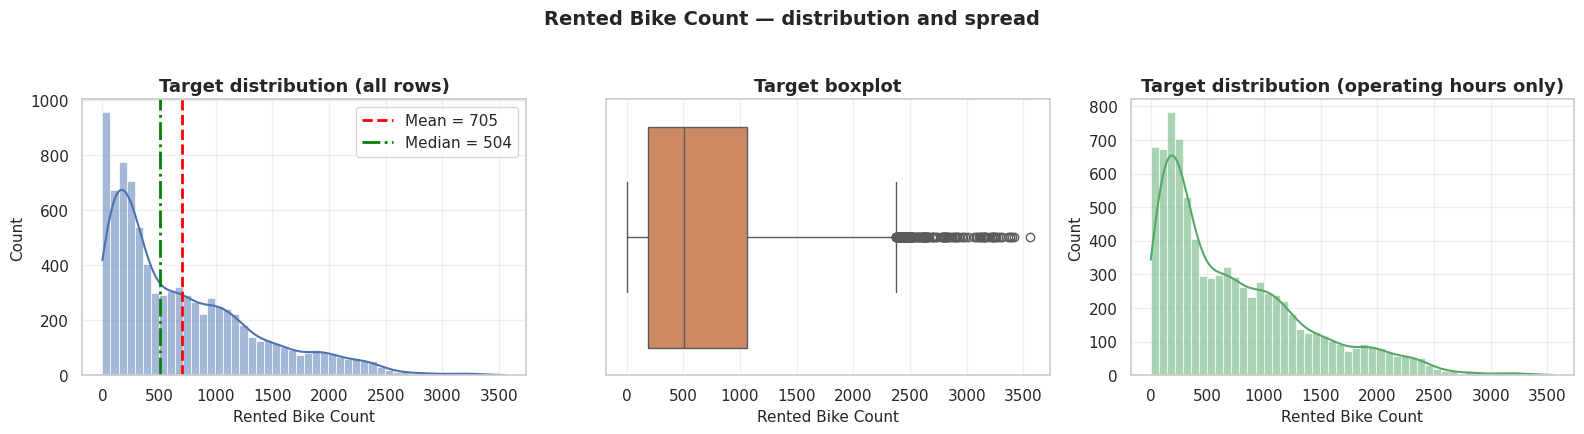

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

sns.histplot(target, bins=50, kde=True, ax=axes[0], color="#4C72B0")
axes[0].axvline(target.mean(), color="red", ls="--", lw=2, label=f"Mean = {target.mean():.0f}")
axes[0].axvline(target.median(), color="green", ls="-.", lw=2, label=f"Median = {target.median():.0f}")
axes[0].set_title("Target distribution (all rows)")
axes[0].set_xlabel("Rented Bike Count")
axes[0].legend()

sns.boxplot(x=target, ax=axes[1], color="#DD8452")
axes[1].set_title("Target boxplot")
axes[1].set_xlabel("Rented Bike Count")

operating = bike_df.loc[bike_df["Functioning Day"] == "Yes", "Rented Bike Count"]
sns.histplot(operating, bins=50, kde=True, ax=axes[2], color="#55A868")
axes[2].set_title("Target distribution (operating hours only)")
axes[2].set_xlabel("Rented Bike Count")

fig.suptitle("Rented Bike Count — distribution and spread",
             y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretation of the three panels.** The left and right panels differ
mainly in the spike at zero: removing non-functioning hours removes the
artificial pile-up at 0 while leaving the overall right-skewed shape intact.
This is visual confirmation that those 295 rows are a separate,
administratively-generated population rather than part of the demand
distribution we are trying to model.

---
## 4.8 Consolidated audit table

In [12]:
audit = audit_table(bike_df)
save_table(audit, "reg_data_quality_audit")
audit

[saved]  outputs/reg_data_quality_audit.csv


,Column,Dtype,Missing,Missing %,Unique,Example value
0,Date,str,0,0.0,365,01/12/2017
1,Rented Bike Count,int64,0,0.0,2166,254
2,Hour,int64,0,0.0,24,0
3,Temperature(°C),float64,0,0.0,546,-5.2
4,Humidity(%),int64,0,0.0,90,37
5,Wind speed (m/s),float64,0,0.0,65,2.2
6,Visibility (10m),int64,0,0.0,1789,2000
7,Dew point temperature(°C),float64,0,0.0,556,-17.6
8,Solar Radiation (MJ/m2),float64,0,0.0,345,0.0
9,Rainfall(mm),float64,0,0.0,61,0.0


---
## 4.9 Audit summary

| Check | Result | Action required |
|---|---|---|
| Missing values (NaN) | 0 of 122,640 cells | None; imputers kept in pipeline for robustness |
| Hidden missing (`?`, `-999`, …) | None found | None |
| Duplicate rows | 0 | None |
| Duplicate `(Date, Hour)` keys | 0 | None |
| Time-series gaps | 0 missing hours, 24 rows/day | None |
| Invalid categories | None | None |
| Physically impossible values | 0 violations | None |
| Dew point > temperature | 0 rows | None |
| Non-functioning hours | 295 rows, target always 0 | **Remove in Notebook 04** |
| Target skew | +1.15, right-skewed | Expect RMSE > MAE; favour non-linear models |
| `Date` stored as text | All 8,760 rows | Convert in Notebook 05 |

The dataset is in unusually good condition. The only substantive issue is the
structural one in §4.6, and it is a modelling decision rather than a data error.

---
## Handover to Notebook 03

We pass the data through **unchanged** — the audit made a decision but
deliberately did not execute it, so that Notebook 03 can still visualise the
non-functioning hours.

In [13]:
save_artifact(bike_df, "reg_02_audited")

print("\nNotebook 02 complete.")
print("Next: 03_regression_eda.ipynb")

[saved]  artifacts/reg_02_audited.joblib

Notebook 02 complete.
Next: 03_regression_eda.ipynb
